# Heart disease risk model (UCI Cleveland, 5 inputs)

Source: UCI Heart Disease (id 45), Cleveland Clinic, 303 patients (US).
MedTrail uses only the 5 inputs that lab reports and the patient profile can provide:

| Column | Meaning | MedTrail source |
|---|---|---|
| age | Age (years) | Patient profile |
| sex | 1 = male, 0 = female | Patient profile |
| trestbps | Resting systolic blood pressure (mm Hg) | Patient profile |
| chol | Serum cholesterol (mg/dL) | Total Cholesterol |
| fbs | Fasting blood sugar > 120 mg/dL (1 = yes, 0 = no) | Fasting Blood Sugar |
| **num** | **Target: 0 = no disease, 1-4 = disease** | |

The other 8 inputs (chest pain type, ECG, exercise test, scans) are not in ordinary lab reports,
so this model is weaker and is shown as indicative only.

In [1]:
import sys
from pathlib import Path

import joblib
import pandas as pd
from sklearn.metrics import roc_auc_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
sys.path.insert(0, str(ROOT))

from src.prediction.train_utils import (compare_models, make_models, risk_level, risk_level_table,
                                        save_model, split_data, test_best_model)
print("Project folder:", ROOT)

Project folder: c:\Users\Amupam Raj\projects\medtrail-ai


In [2]:
df = pd.read_csv(ROOT / "datasets" / "raw" / "heart" / "heart_cleveland.csv")
print(df.shape)

df["target"] = (df["num"] > 0).astype(int)     # 1, 2, 3, 4 all mean "heart disease"
print(df["target"].value_counts())
print(f"Heart disease rate: {df['target'].mean():.1%}")

(303, 14)
target
0    164
1    139
Name: count, dtype: int64
Heart disease rate: 45.9%


In [3]:
FEATURES = ["age", "sex", "trestbps", "chol", "fbs"]

print("Missing values:", df[FEATURES].isna().sum().to_dict())
print("\nMedian value (0 = no disease, 1 = disease):")
print(df.groupby("target")[FEATURES].median())

single = {}
for col in FEATURES:
    auc = roc_auc_score(df["target"], df[col])
    single[col] = max(auc, 1 - auc)
print("\nHow well each input separates heart disease on its own:")
print(pd.Series(single).round(3).sort_values(ascending=False))

Missing values: {'age': 0, 'sex': 0, 'trestbps': 0, 'chol': 0, 'fbs': 0}

Median value (0 = no disease, 1 = disease):
         age  sex  trestbps   chol  fbs
target                                 
0       52.0  1.0     130.0  234.5  0.0
1       58.0  1.0     130.0  249.0  0.0

How well each input separates heart disease on its own:
age         0.637
sex         0.630
trestbps    0.574
chol        0.570
fbs         0.509
dtype: float64


In [4]:
X = df[FEATURES]
y = df["target"]
X_train, X_test, y_train, y_test = split_data(X, y)
print("Training patients:", len(X_train), "| Test patients:", len(X_test))

models = make_models()
cv_results = compare_models(models, X_train, y_train)
cv_results

Training patients: 242 | Test patients: 61


,roc_auc,accuracy,precision,recall,f1,roc_auc_spread
model,,,,,,
Logistic Regression,0.693,0.648,0.629,0.604,0.612,0.068
XGBoost,0.675,0.611,0.575,0.575,0.574,0.063
Random Forest,0.674,0.624,0.614,0.514,0.556,0.047


In [5]:
ALL_13 = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
          "thalach", "exang", "oldpeak", "slope", "ca", "thal"]
cv_all_13 = compare_models(make_models(), df.loc[X_train.index, ALL_13], y_train)
print("Same training patients, all 13 inputs (NOT used by MedTrail):")
cv_all_13

Same training patients, all 13 inputs (NOT used by MedTrail):


,roc_auc,accuracy,precision,recall,f1,roc_auc_spread
model,,,,,,
Logistic Regression,0.896,0.826,0.844,0.765,0.801,0.015
Random Forest,0.891,0.814,0.826,0.756,0.786,0.028
XGBoost,0.864,0.789,0.774,0.774,0.770,0.017


Best model (highest cross-validated ROC-AUC): Logistic Regression
Results on the 61 test patients (used only once):
  roc_auc   0.701
  accuracy  0.656
  precision 0.640
  recall    0.571
  f1        0.604


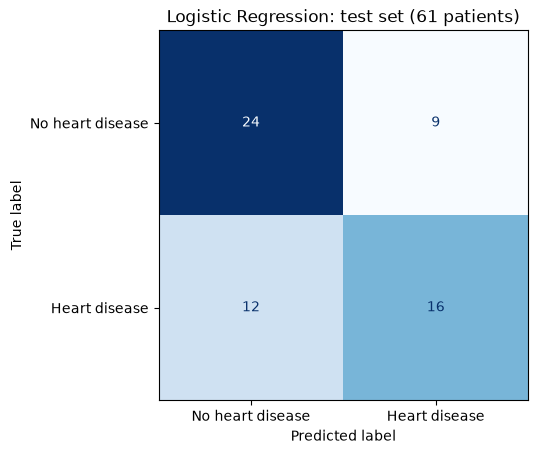

In [6]:
best_name, best_model, proba, test_metrics = test_best_model(
    cv_results, models, X_train, y_train, X_test, y_test, labels=["No heart disease", "Heart disease"]
)

In [7]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split

aucs = []
for seed in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    model = clone(best_model).fit(Xa, ya)
    aucs.append(roc_auc_score(yb, model.predict_proba(Xb)[:, 1]))

print("Test ROC-AUC on 10 different splits:", [round(a, 2) for a in aucs])
print(f"Average {pd.Series(aucs).mean():.3f}, lowest {min(aucs):.3f}, highest {max(aucs):.3f}")

Test ROC-AUC on 10 different splits: [0.7, 0.7, 0.74, 0.68, 0.74, 0.71, 0.68, 0.73, 0.71, 0.68]
Average 0.705, lowest 0.675, highest 0.741


In [8]:
risk_level_table(proba, y_test)

,patients,actually_had_disease
risk_level,,
Low,17,18%
Moderate,25,48%
High,19,68%


In [9]:
save_model(ROOT / "models", "heart", best_name, best_model, FEATURES, cv_results, test_metrics, notes={
    "dataset": "UCI Heart Disease (id 45), Cleveland Clinic, 303 patients (US)",
    "target": "1 = num 1-4 (disease), 0 = num 0",
    "feature_meaning": {
        "age": "Age (years)", "sex": "1 = male, 0 = female",
        "trestbps": "Resting systolic blood pressure (mm Hg)", "chol": "Total Cholesterol (mg/dL)",
        "fbs": "1 if Fasting Blood Sugar > 120 mg/dL, else 0",
    },
    "cv_roc_auc_with_all_13_inputs": float(cv_all_13["roc_auc"].iloc[0]),
    "repeated_split_test_roc_auc": {
        "average": round(float(pd.Series(aucs).mean()), 3),
        "lowest": round(min(aucs), 3),
        "highest": round(max(aucs), 3),
    },
    "limitation": "Uses 5 of 13 inputs because the other 8 need ECG, exercise tests or scans. "
                  "Weakest MedTrail model; show as indicative only.",
})

Saved: heart_pipeline.joblib and heart_metrics.json


In [10]:
loaded = joblib.load(ROOT / "models" / "heart_pipeline.joblib")
samples = pd.DataFrame([
    {"age": 62, "sex": 1, "trestbps": 160, "chol": 290, "fbs": 1},
    {"age": 35, "sex": 0, "trestbps": 115, "chol": 180, "fbs": 0},
])
for name, p in zip(["Older man, high BP and cholesterol", "Young woman, normal values"],
                   loaded.predict_proba(samples)[:, 1]):
    print(f"{name}: probability {p:.2f} -> {risk_level(p)} risk")

Older man, high BP and cholesterol: probability 0.74 -> High risk
Young woman, normal values: probability 0.05 -> Low risk
